#### Did not multiplied the logits by 50 made it less deterministic.

>>> Running 4-Way Accuracy Comparison on cuda:3


Evaluating x=0.9: 100%|██████████| 4/4 [00:00<00:00, 45.72it/s]


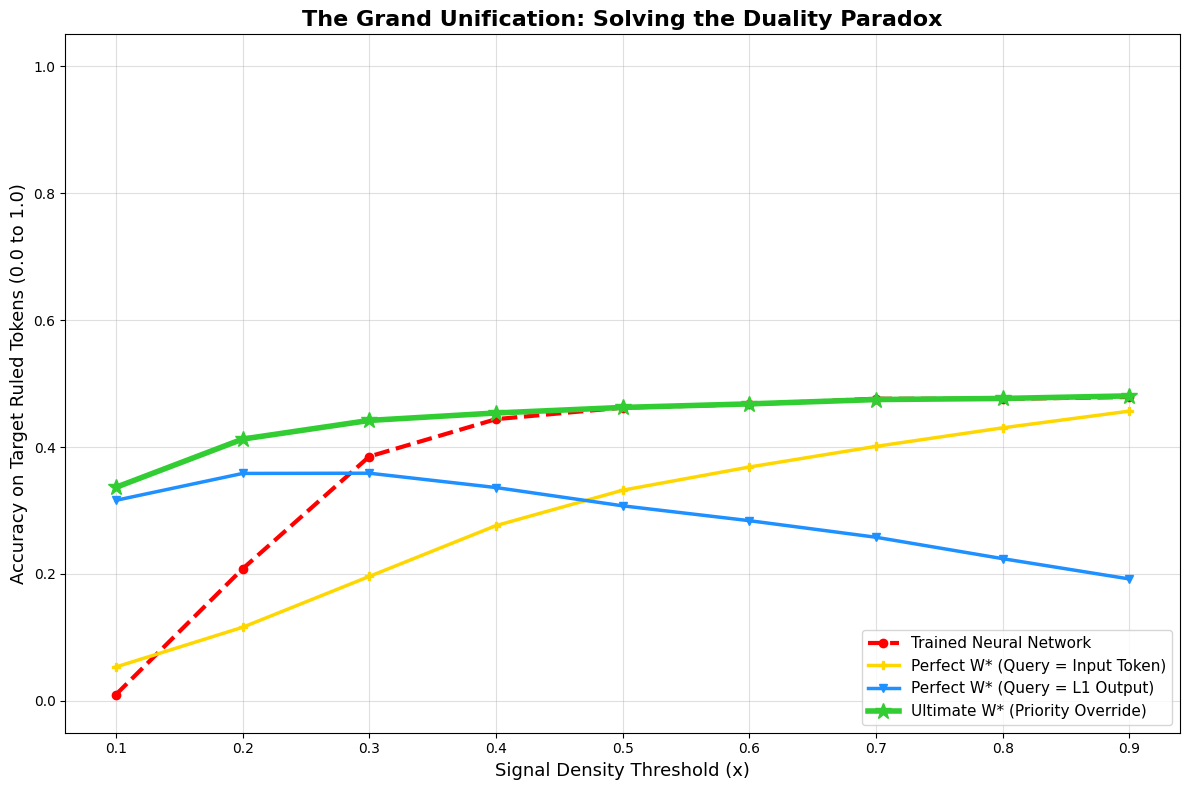

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': '/home/hariguru/ashutosh/expts/experiment_artifacts',
    'output_dir': 'artifacts',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], 
    'num_test_seqs': 1000,   
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITIONS ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)
        
    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights
        
class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        return self.fc_out(x_stream), [a1, a2]
        
# The Perfect Theoretical Model (W*) - Configurable for all 3 strategies
class PerfectInductionTransformer(nn.Module):
    def __init__(self, query_type='input'):
        super().__init__()
        self.query_type = query_type
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.attn_dim = self.initial_dim  
        self.layer1 = ConcatAttentionBlock(self.initial_dim, self.attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, CONFIG['total_vocab'], bias=False)
        self._set_perfect_weights()
    
    def _set_perfect_weights(self):
        V = CONFIG['total_vocab']
        T = CONFIG['seq_len']
        D = self.attn_dim
        V_rule = CONFIG['vocab_set1']
        
        # --- LAYER 1: Strict Signal Retriever ---
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        Target1 = torch.zeros(D, D)
        for id_k in range(V_rule, V): Target1[id_k, :] = -1e9
        alpha = 20.0
        for t_q in range(T):
            for t_k in range(T):
                if t_q == t_k: Target1[V + t_k, V + t_q] = -1e9  
                else: Target1[V + t_k, V + t_q] = -alpha * (t_q - t_k) 
        self.layer1.W_k.weight.data = Target1.t()
        W_v1 = torch.zeros(D, D)
        W_v1[0:V, 0:V] = torch.eye(V) 
        self.layer1.W_v.weight.data = W_v1
        self.layer1.W_o.weight.data = torch.eye(D) 
        
        # --- LAYER 2: The Configurable Induction Head ---
        in2 = D + D
        W_q2 = torch.zeros(D, in2)
        
        if self.query_type == 'input':
            W_q2[0:V, 0:V] = torch.eye(V) * (D ** 0.5) * 50.0 
            for v in range(V_rule): W_q2[V_rule, v] = (D ** 0.5) * 10.0 
            
        elif self.query_type == 'l1_out':
            W_q2[0:V, D:D+V] = torch.eye(V) * (D ** 0.5) * 50.0 
            for v in range(V_rule): W_q2[V_rule, D + v] = (D ** 0.5) * 10.0 
            
        elif self.query_type == 'ultimate':
            # THE ULTIMATE PRIORITY OVERRIDE
            # Priority 1: Current Input (Massive Weight)
            W_q2[0:V_rule, 0:V_rule] = torch.eye(V_rule) * (D ** 0.5) * 1000.0 
            # Priority 2: L1 Output (Fallback Weight)
            W_q2[0:V_rule, D:D+V_rule] = torch.eye(V_rule) * (D ** 0.5) * 50.0 
            # Trigger dimension to activate noise filter
            for v in range(V): W_q2[V_rule, v] = (D ** 0.5) * 10.0 
                
        self.layer2.W_q.weight.data = W_q2
        
        W_k2 = torch.zeros(D, in2)
        W_k2[0:V, D:D+V] = torch.eye(V) 
        # Noise Filter
        for v in range(V_rule, V): W_k2[V_rule, v] = -50000.0 
        self.layer2.W_k.weight.data = W_k2
        
        W_v2 = torch.zeros(D, in2)
        W_v2[0:V, 0:V] = torch.eye(V) 
        self.layer2.W_v.weight.data = W_v2
        self.layer2.W_o.weight.data = torch.eye(D) 
        
        # --- FINAL OUTPUT: The Logit Scaler ---
        W_fc = torch.zeros(V, in2 + D)
        W_fc[0:V, in2:in2+V] = torch.eye(V) # * 50.0 
        self.fc_out.weight.data = W_fc

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        return self.fc_out(x_stream), [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. ACCURACY-ONLY ANALYSIS ---
def run_accuracy_only_analysis():
    print(f">>> Running 4-Way Accuracy Comparison on {CONFIG['device']}")
    final_stats = {}
    
    perf_input_model = PerfectInductionTransformer(query_type='input').to(CONFIG['device']).eval()
    perf_l1_model = PerfectInductionTransformer(query_type='l1_out').to(CONFIG['device']).eval()
    perf_ult_model = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device']).eval()

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_ruled_targets = 0
        total_correct_trained = 0
        total_correct_perf_input, total_correct_perf_l1, total_correct_perf_ult = 0, 0, 0
        trained_model_loaded = False

        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x, batch_y = batch_x.to(CONFIG['device']), batch_y.to(CONFIG['device'])
            is_ruled_target = batch_y < CONFIG['vocab_set1']
            total_ruled_targets += is_ruled_target.sum().item()

            with torch.no_grad():
                total_correct_perf_input += ((perf_input_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()
                total_correct_perf_l1 += ((perf_l1_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()
                total_correct_perf_ult += ((perf_ult_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()

            if trained_model_loaded:
                with torch.no_grad():
                    total_correct_trained += ((trained_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()

        final_stats[x] = {
            'trained_acc': total_correct_trained / total_ruled_targets if trained_model_loaded else None,
            'perf_input_acc': total_correct_perf_input / total_ruled_targets,
            'perf_l1_acc': total_correct_perf_l1 / total_ruled_targets,
            'perf_ult_acc': total_correct_perf_ult / total_ruled_targets
        }
        
        if trained_model_loaded: del trained_model
        torch.cuda.empty_cache()

    return final_stats

# --- 5. CLEAN PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    trained_x = [x for x in x_vals if stats[x]['trained_acc'] is not None]
    trained_acc = [stats[x]['trained_acc'] for x in trained_x]
    
    perf_input_acc = [stats[x]['perf_input_acc'] for x in x_vals]
    perf_l1_acc = [stats[x]['perf_l1_acc'] for x in x_vals]
    perf_ult_acc = [stats[x]['perf_ult_acc'] for x in x_vals]

    plt.figure(figsize=(12, 8))

    plt.plot(trained_x, trained_acc, color='red', marker='o', linestyle='--', linewidth=3, label='Trained Neural Network')
    plt.plot(x_vals, perf_input_acc, color='gold', marker='P', linestyle='-', linewidth=2.5, label='Perfect W* (Query = Input Token)')
    plt.plot(x_vals, perf_l1_acc, color='dodgerblue', marker='v', linestyle='-', linewidth=2.5, label='Perfect W* (Query = L1 Output)')
    
    # THE ULTIMATE MODEL
    plt.plot(x_vals, perf_ult_acc, color='limegreen', marker='*', markersize=12, linestyle='-', linewidth=4, label='Ultimate W* (Priority Override)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Accuracy on Target Ruled Tokens (0.0 to 1.0)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.ylim(-0.05, 1.05)
    
    plt.legend(loc='lower right', fontsize=11)
    plt.title("The Grand Unification: Solving the Duality Paradox", fontsize=16, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/accuracy_comparison_ultimate.png")
    plt.show()

if __name__ == "__main__":
    stats = run_accuracy_only_analysis()
    plot_results(stats)

### Cross Entropy Loss:

>>> Running CE Loss Comparison (Scale=50 vs Scale=1 vs Trained) on cuda:3


Evaluating CE Loss x=0.9: 100%|███████████████████| 4/4 [00:00<00:00, 12.04it/s]


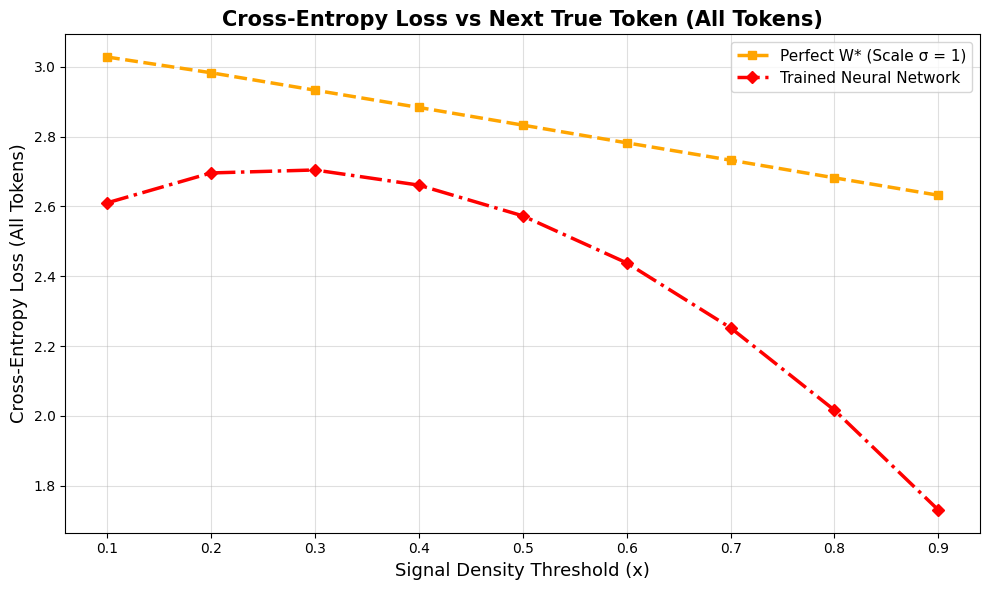

In [32]:
# --- 6. CE LOSS COMPARISON (Scaled vs Unscaled vs Trained) ---
def run_ce_loss_comparison():
    print(f">>> Running CE Loss Comparison (Scale=50 vs Scale=1 vs Trained) on {CONFIG['device']}")
    
    # 1. Initialize two "Ultimate" (Green) models
    model_scaled = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device']).eval()
    model_unscaled = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device']).eval()
    
    # 2. Modify the unscaled model's unembedding matrix to remove the 50x multiplier
    V = CONFIG['total_vocab']
    D = model_unscaled.attn_dim
    in2 = D + D
    
    W_fc_unscaled = torch.zeros(V, in2 + D, device=CONFIG['device'])
    W_fc_unscaled[0:V, in2:in2+V] = torch.eye(V, device=CONFIG['device']) * 1.0  
    model_unscaled.fc_out.weight.data = W_fc_unscaled

    loss_scaled_list = []
    loss_unscaled_list = []
    loss_trained_list = []
    
    # 3. Path to your trained model artifacts
    trained_model_dir = "/home/hariguru/ashutosh/expts/experiment_artifacts"

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        # Attempt to load the trained model for the current threshold
        trained_model_loaded = False
        model_path = os.path.join(trained_model_dir, f"model_x_{x}.pth")
        
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True
        else:
            print(f"Warning: Trained model not found at {model_path}")

        total_loss_scaled = 0.0
        total_loss_unscaled = 0.0
        total_loss_trained = 0.0
        num_batches = 0

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating CE Loss x={x}"):
            batch_x, batch_y = batch_x.to(CONFIG['device']), batch_y.to(CONFIG['device'])
            
            with torch.no_grad():
                logits_scaled, _ = model_scaled(batch_x)
                logits_unscaled, _ = model_unscaled(batch_x)
                
                # Flatten spatial dimensions for Cross Entropy
                # PyTorch F.cross_entropy mathematically handles the one-hot target equivalent 
                # internally when passing class indices
                logits_scaled = logits_scaled.view(-1, V)
                logits_unscaled = logits_unscaled.view(-1, V)
                targets = batch_y.view(-1)
                
                # CE Loss evaluated across ALL tokens (no masking)
                loss_s = F.cross_entropy(logits_scaled, targets)
                loss_u = F.cross_entropy(logits_unscaled, targets)
                
                total_loss_scaled += loss_s.item()
                total_loss_unscaled += loss_u.item()
                
                # Evaluate trained model if available
                if trained_model_loaded:
                    logits_trained, _ = trained_model(batch_x)
                    logits_trained = logits_trained.view(-1, V)
                    loss_t = F.cross_entropy(logits_trained, targets)
                    total_loss_trained += loss_t.item()
                    
                num_batches += 1

        loss_scaled_list.append(total_loss_scaled / num_batches)
        loss_unscaled_list.append(total_loss_unscaled / num_batches)
        
        if trained_model_loaded:
            loss_trained_list.append(total_loss_trained / num_batches)
            del trained_model
        else:
            loss_trained_list.append(None)
            
        torch.cuda.empty_cache()

    return loss_scaled_list, loss_unscaled_list, loss_trained_list

def plot_ce_loss(loss_scaled, loss_unscaled, loss_trained):
    x_vals = CONFIG['thresholds']
    
    # Filter out thresholds where the trained model wasn't found
    trained_x = [x for x, val in zip(x_vals, loss_trained) if val is not None]
    trained_loss = [val for val in loss_trained if val is not None]
    
    plt.figure(figsize=(10, 6))
    
    # plt.plot(x_vals, loss_scaled, color='blue', marker='o', linestyle='-', linewidth=2.5, 
    #          label='Perfect W* (Scale σ = 50)')
    
    plt.plot(x_vals, loss_unscaled, color='orange', marker='s', linestyle='--', linewidth=2.5, 
             label='Perfect W* (Scale σ = 1)')
    
    if trained_loss:
        plt.plot(trained_x, trained_loss, color='red', marker='D', linestyle='-.', linewidth=2.5, 
                 label='Trained Neural Network')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Cross-Entropy Loss (All Tokens)", fontsize=13)
    plt.grid(True, alpha=0.4)
    
    plt.legend(loc='upper right', fontsize=11)
    plt.title("Cross-Entropy Loss vs Next True Token (All Tokens)", fontsize=15, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/ce_loss_scaling_vs_trained.png")
    plt.show()

# Execute the analysis
loss_scaled, loss_unscaled, loss_trained = run_ce_loss_comparison()
plot_ce_loss(loss_scaled, loss_unscaled, loss_trained)